# Multiple Linear Regression

**Goal:** predict a house's price from **several** inputs at once: size, bedrooms and age.

**The idea:** the same straight-line model, with one weight per input:

$$\hat{y} = b + w_1 x_1 + w_2 x_2 + w_3 x_3$$

Each weight tells you how much the price changes when **that input goes up by 1 while the others stay the same**.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'numpy'

## 2. Load the data

In [ ]:
df = pd.read_csv("house_prices.csv")
df.head()

,size_m2,bedrooms,age_years,price_thousands
0,85.8,2,29,110.30
1,178.0,2,28,212.87
2,143.5,1,13,200.79
3,124.1,3,17,180.44
4,121.0,3,26,188.97


## 3. Explore: how does each input relate to price?

The correlation table shows which inputs move together with price (+1 or -1 is a strong relationship, 0 is none).

In [ ]:
df.corr().round(2)

,size_m2,bedrooms,age_years,price_thousands
size_m2,1.00,0.78,-0.00,0.97
bedrooms,0.78,1.00,0.00,0.80
age_years,-0.00,0.00,1.00,-0.11
price_thousands,0.97,0.80,-0.11,1.00


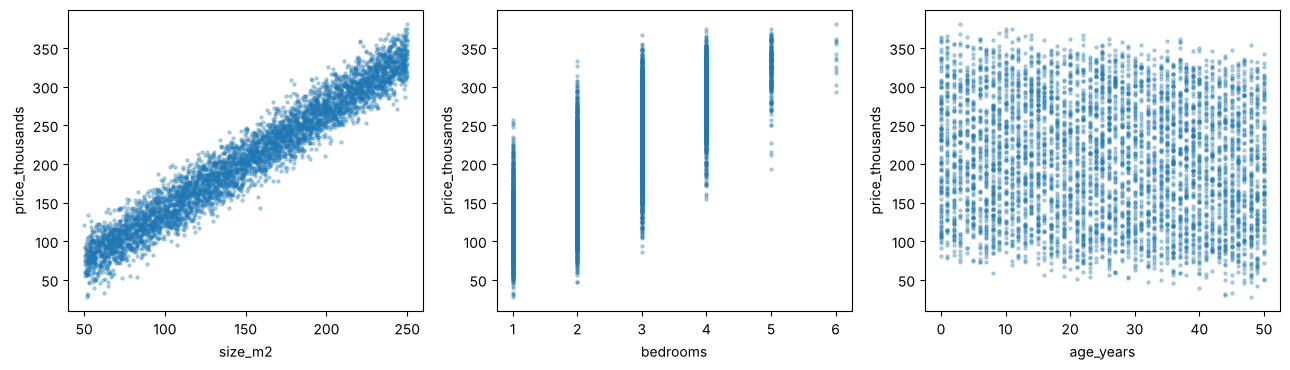

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col in zip(axes, ["size_m2", "bedrooms", "age_years"]):
    ax.scatter(df[col], df["price_thousands"], s=5, alpha=0.3)
    ax.set_xlabel(col)
    ax.set_ylabel("price_thousands")
plt.tight_layout()
plt.show()

## 4. Split into training and test sets (70% / 30%)

In [ ]:
features = ["size_m2", "bedrooms", "age_years"]
X = df[features].to_numpy()
y = df["price_thousands"].to_numpy()

rng = np.random.default_rng(0)
idx = rng.permutation(len(y))
cut = int(0.7 * len(y))
train, test = idx[:cut], idx[cut:]

X_train, y_train = X[train], y[train]
X_test, y_test = X[test], y[test]
print("Training rows:", len(train), "  Test rows:", len(test))

Training rows: 3500   Test rows: 1500


## 5. Train the model

With many inputs we solve for all the weights at once. We add a column of 1s so the intercept $b$ is learned too (this is the *normal equation*, solved here with `np.linalg.lstsq`).

In [ ]:
Xb = np.hstack([np.ones((len(X_train), 1)), X_train])
beta, *_ = np.linalg.lstsq(Xb, y_train, rcond=None)
b, w = beta[0], beta[1:]

print(f"Intercept: {b:.2f}")
for name, wi in zip(features, w):
    print(f"{name:<10} {wi:+.3f}")

Intercept: 19.93
size_m2    +1.192
bedrooms   +8.466
age_years  -0.590


**Reading the weights**

- `size_m2`: each extra m² adds this much to the price, with bedrooms and age fixed.
- `bedrooms`: each extra bedroom adds this much, with size and age fixed.
- `age_years`: a negative weight means older houses are cheaper.

## 6. Predict on the test set

In [ ]:
pred = b + X_test @ w

## 7. Evaluate

**Adjusted R²** is R² corrected for the number of inputs. Plain R² never goes down when you add an input, even a useless one. Adjusted R² only improves if the new input genuinely helps.

$$\text{Adj. } R^2 = 1 - (1-R^2)\frac{n-1}{n-p-1}$$

In [ ]:
residuals = y_test - pred
n, p = len(y_test), X.shape[1]

mae = np.mean(np.abs(residuals))
mse = np.mean(residuals ** 2)
rmse = np.sqrt(mse)
r2 = 1 - np.sum(residuals ** 2) / np.sum((y_test - y_test.mean()) ** 2)
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print(f"MAE         = {mae:.2f}")
print(f"MSE         = {mse:.2f}")
print(f"RMSE        = {rmse:.2f}")
print(f"R2          = {r2:.3f}")
print(f"Adjusted R2 = {adj_r2:.3f}")

MAE         = 11.88
MSE         = 220.22
RMSE        = 14.84
R2          = 0.963
Adjusted R2 = 0.963


## 8. Plots

The **residual plot** should look like random noise around 0. A curve or fan shape would mean the model is missing something.

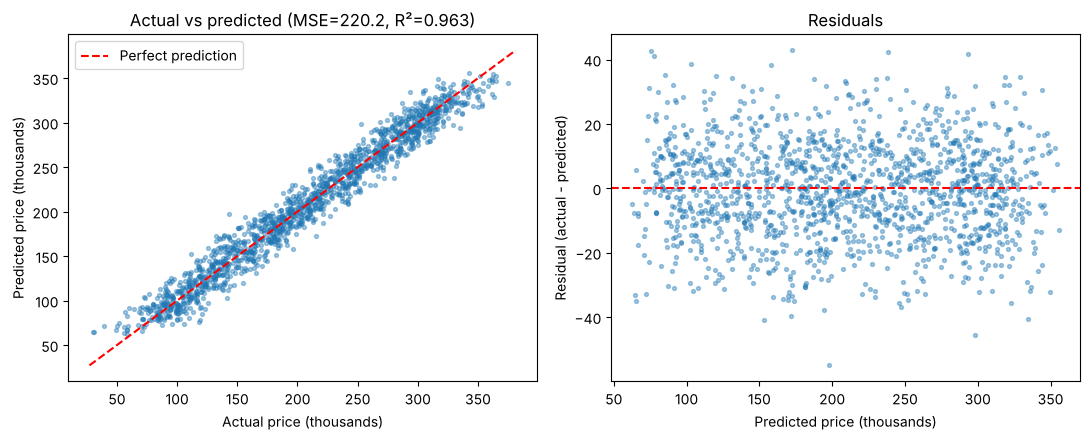

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter(y_test, pred, s=8, alpha=0.4)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--", label="Perfect prediction")
axes[0].set_xlabel("Actual price (thousands)")
axes[0].set_ylabel("Predicted price (thousands)")
axes[0].set_title(f"Actual vs predicted (MSE={mse:.1f}, R²={r2:.3f})")
axes[0].legend()

axes[1].scatter(pred, residuals, s=8, alpha=0.4)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Predicted price (thousands)")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Residuals")

plt.tight_layout()
plt.show()

## 9. Compare with the simple model

We refit using size only and compare the test scores side by side.

In [ ]:
def fit_and_score(cols):
    Xtr = np.hstack([np.ones((len(train), 1)), X[train][:, cols]])
    beta, *_ = np.linalg.lstsq(Xtr, y_train, rcond=None)
    p_hat = beta[0] + X[test][:, cols] @ beta[1:]
    res = y_test - p_hat
    return np.mean(res ** 2), 1 - np.sum(res ** 2) / np.sum((y_test - y_test.mean()) ** 2)

results = pd.DataFrame(
    [fit_and_score([0]), fit_and_score([0, 1, 2])],
    index=["Simple (size only)", "Multiple (size, bedrooms, age)"],
    columns=["MSE", "R2"],
).round(3)
results

,MSE,R2
Simple (size only),321.249,0.946
"Multiple (size, bedrooms, age)",220.224,0.963


## 10. Conclusion

- Adding bedrooms and age lowers the error (MSE drops from about 321 to about 220) and raises R² from about 0.946 to about 0.963.
- The weights are close to the values used to create the data (about 1.2 per m², 8 per bedroom, -0.6 per year), so the model recovered the real pattern.
- Remember that linear regression predicts a **number**. To predict a **category** such as pass or fail, we use **logistic regression** (next notebook).